# Cognifyz Data Analysis Internship — Level 2

## Data Analysis Internship Project

**Intern:** Anshuman Ray  
**Organization:** Cognifyz IT Solutions Pvt. Ltd.  
**Role:** Data Analysis Intern  
**Level:** Level 2 (Restaurant Ratings, Cuisine Combination, Geographic Analysis, Restaurant Chains)

## 1. Internship Context

This notebook is the second half of the official **Cognifyz IT Solutions Data Analysis internship** project. It continues from **Level 1** (Top Cuisines, City Analysis, Price Range Distribution, Online Delivery) and deepens the analysis into ratings, cuisine pairing, geography, and chains.

> **Note on independence:** although this notebook shares the same dataset and cleaning steps as Level 1, it is written to be fully understandable on its own. Where a concept was introduced in Level 1, it is briefly re-explained here.

## 2. Level 2 Overview & Objectives

Level 2 extends the analysis to four more demanding tasks:

| Task | Title | Analytical Question |
|------|-------|--------------------|
| 1 | **Restaurant Ratings** | How are aggregate ratings distributed, and what is the average vote count? |
| 2 | **Cuisine Combination** | What are the most common cuisine pairings, and do some rate higher? |
| 3 | **Geographic Analysis** | Where are restaurants located, and where do they cluster? |
| 4 | **Restaurant Chains** | Which restaurant names appear as chains, and how do they perform? |

The overarching objective is to move from *describing* the dataset (Level 1) to *investigating relationships* — how ratings behave, how cuisines combine, and how location and brand affect performance.

## 3. Dataset Overview

The same restaurant dataset is used here. The columns most relevant to Level 2 are:

- `Aggregate rating` — the restaurant's overall rating (0.0–5.0)
- `Rating text` — a categorical label (Excellent / Very Good / Good / Average / Poor / Not rated)
- `Rating color` — the colour associated with the rating band
- `Votes` — total number of votes/reviews received
- `Cuisines` — comma-separated cuisine list
- `Restaurant Name` — used to detect chains
- `Longitude`, `Latitude` — restaurant coordinates
- `Country Code`, `City` — geographic context

**Important:** `Aggregate rating`, `Rating text`, and `Rating color` are **different columns** and are treated appropriately — we analyse the numeric rating directly and never conflate it with the text label or colour.

In [1]:
# Standard data science libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

import warnings
warnings.filterwarnings('ignore')

# Geographic visualisation library (used in Task 3)
try:
    import folium
    HAS_FOLIUM = True
except ImportError:
    HAS_FOLIUM = False
    print('folium not installed - geographic analysis will fall back to a scatter plot.')

print('Libraries imported successfully.')

folium not installed - geographic analysis will fall back to a scatter plot.
Libraries imported successfully.


In [2]:
from pathlib import Path
import pandas as pd

# Find the dataset without relying on a fixed drive path
filename = "Dataset_real.csv"
search_roots = [Path.cwd(), *Path.cwd().parents]

possible_paths = []

for root in search_roots:
    possible_paths.extend([
        root / "data" / filename,
        root / "Cognifyz-Data-Analysis" / "data" / filename
    ])

dataset_path = next(
    (p.resolve() for p in possible_paths
     if p.is_file() and p.stat().st_size > 0),
    None
)

if dataset_path is None:
    raise FileNotFoundError(
        "Dataset_real.csv was not found. Check the data folder."
    )

try:
    df = pd.read_csv(dataset_path, encoding="utf-8")
except UnicodeDecodeError:
    df = pd.read_csv(dataset_path, encoding="latin-1")

print("Dataset loaded successfully!")
print("Dataset path:", dataset_path)
print("Shape (rows, columns):", df.shape)

df.head()

Dataset loaded successfully!
Dataset path: D:\Cognifyz_Data_Analysis_Internship\Cognifyz-Data-Analysis\data\Dataset_real.csv
Shape (rows, columns): (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


## 4. Initial Inspection

We confirm the structure of the data before analysis.

In [3]:
df.head(5)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [5]:
# Summary statistics for numerical columns
df.describe()

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


### Observations

- `Aggregate rating` spans 0.0–5.0. A rating of **0.0** corresponds to **"Not rated"** — these are unrated restaurants, not genuinely bad ones, and are handled accordingly in every rating calculation.
- `Votes` is heavily right-skewed (mean >> median): a few very popular restaurants dominate total votes.
- `Longitude`/`Latitude` include some rows at exactly `(0, 0)`, which are invalid and excluded from the geographic analysis.

## 5. Data Quality Check

Quantify missing values, duplicates, and the state of the columns used by Level 2.

In [6]:
# Missing values per column
missing = df.isnull().sum()
missing_df = pd.DataFrame({'Column': missing.index, 'Missing': missing.values,
                           'Percent': (missing.values / len(df) * 100).round(2)})
missing_df[missing_df['Missing'] > 0]

,Column,Missing,Percent
9,Cuisines,9,0.09


In [7]:
# Duplicate rows
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate Restaurant IDs:', df['Restaurant ID'].duplicated().sum())

Duplicate rows: 0
Duplicate Restaurant IDs: 0


In [8]:
# State of key rating/cuisine/location columns
print('Rating text distribution:')
print(df['Rating text'].value_counts().to_string())
print("\nUnique countries (Country Code):", df['Country Code'].nunique())
print("Unique cities:", df['City'].nunique())
print("\nInvalid coordinates (both longitude and latitude == 0):",
      ((df['Longitude'] == 0) & (df['Latitude'] == 0)).sum())

Rating text distribution:
Rating text
Average      3737
Not rated    2148
Good         2100
Very Good    1079
Excellent     301
Poor          186

Unique countries (Country Code): 15
Unique cities: 141

Invalid coordinates (both longitude and latitude == 0): 497


## 6. Data Cleaning

Applying the same conservative, transparent cleaning as Level 1 so both notebooks are consistent.

In [9]:
clean_df = df.copy()

# Flag unrated restaurants
clean_df['is_rated'] = clean_df['Aggregate rating'] > 0

# Standardise whitespace on text fields (keeps missing values intact)
clean_df['Cuisines'] = clean_df['Cuisines'].str.strip()
for col in ['Restaurant Name', 'City']:
    clean_df[col] = clean_df[col].astype(str).str.strip()

# Keep a subset of valid-coordinate rows for geography (separate from general cleaning)
geo_df = clean_df[(clean_df['Longitude'] != 0) & (clean_df['Latitude'] != 0)].copy()

print('Cleaned working frame rows:', len(clean_df))
print('Rows with valid coordinates (for geography):', len(geo_df))
print('Missing Cuisines after cleaning:', clean_df['Cuisines'].isnull().sum())

Cleaned working frame rows: 9551
Rows with valid coordinates (for geography): 9052
Missing Cuisines after cleaning: 9


### Cleaning decisions

- No rows are dropped by the general cleaning.
- Missing `Cuisines` values are retained and excluded only within cuisine-specific analyses.
- Unrated restaurants are flagged via `is_rated`, not deleted.
- For the geographic task, rows with invalid `(0, 0)` coordinates are placed in a separate `geo_df` so the map only uses trustworthy coordinates.

---

# 7. Task 1 — Restaurant Ratings

## What we are trying to determine

1. The **distribution** of aggregate ratings.
2. The **most common rating range**.
3. The **average number of votes** received by restaurants.

## Methodology

- We analyse `Aggregate rating` on the **rated** subset (rating > 0) so 'Not rated' rows do not distort the distribution.
- We partition the rating scale into bands (0–1, 1–2, 2–3, 3–4, 4–5) to find where ratings concentrate.
- Votes are summarised with the mean, and we visualise their (heavily skewed) distribution.

In [10]:
# Rated restaurants only (rating > 0)
rated = clean_df[clean_df['is_rated']].copy()
print('Rated restaurants:', len(rated))
print('Unrated restaurants excluded:', len(clean_df) - len(rated))

Rated restaurants: 7403
Unrated restaurants excluded: 2148


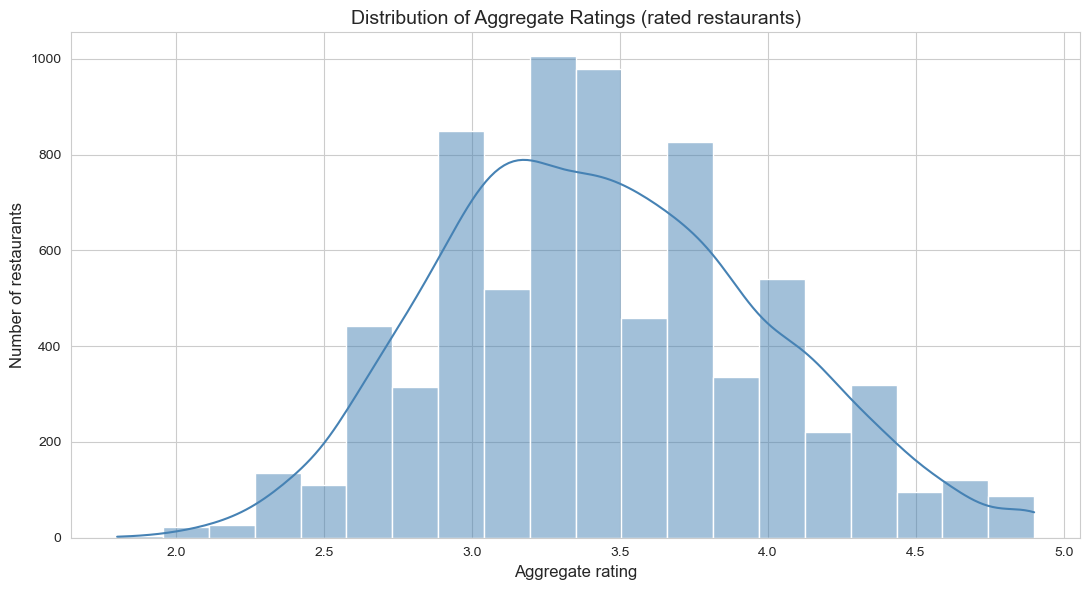

In [11]:
# Histogram + KDE of aggregate rating
plt.figure(figsize=(11, 6))
sns.histplot(rated['Aggregate rating'], bins=20, kde=True, color='steelblue')
plt.title('Distribution of Aggregate Ratings (rated restaurants)')
plt.xlabel('Aggregate rating')
plt.ylabel('Number of restaurants')
plt.tight_layout()
plt.show()

In [12]:
# Partition ratings into bands to find the most common range
bins = [0, 1, 2, 3, 4, 5]
labels = ['0-1', '1-2', '2-3', '3-4', '4-5']
rated['rating_band'] = pd.cut(rated['Aggregate rating'], bins=bins, labels=labels, include_lowest=True)
band_counts = rated['rating_band'].value_counts().sort_index()
band_pct = (band_counts / len(rated) * 100).round(2)

band_table = pd.DataFrame({'Rating band': band_counts.index,
                           'Restaurants': band_counts.values,
                           'Percent_of_rated': band_pct.values})
print('RATING BAND DISTRIBUTION:')
band_table

RATING BAND DISTRIBUTION:


,Rating band,Restaurants,Percent_of_rated
0,0-1,0,0.00
1,1-2,10,0.14
2,2-3,1891,25.54
3,3-4,4388,59.27
4,4-5,1114,15.05


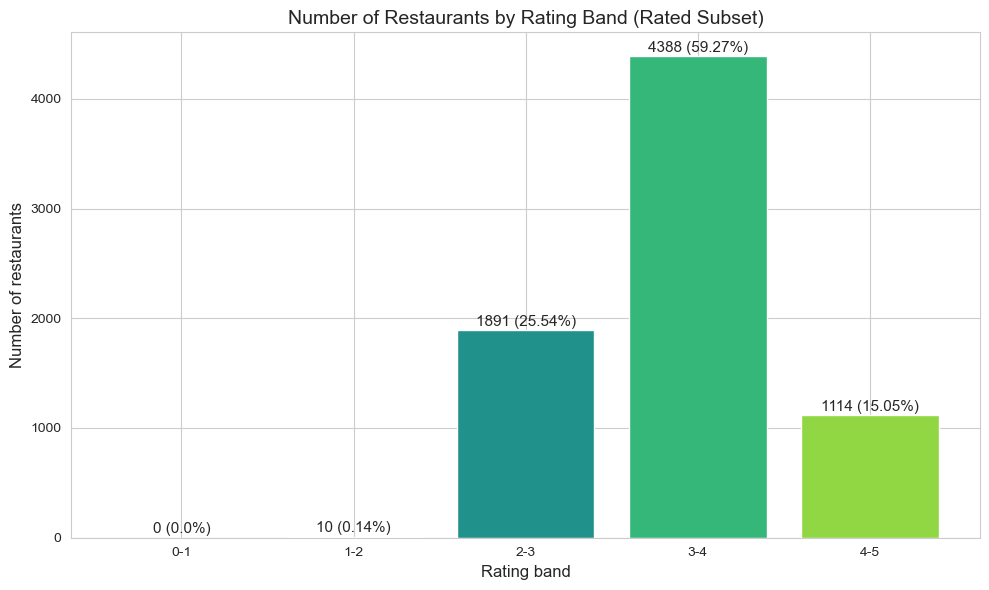

In [13]:
# Visualise the rating bands
plt.figure(figsize=(10, 6))
bars = plt.bar(band_counts.index, band_counts.values, color=sns.color_palette('viridis', len(band_counts)))
plt.xlabel('Rating band')
plt.ylabel('Number of restaurants')
plt.title('Number of Restaurants by Rating Band (Rated Subset)')
for bar, pct in zip(bars, band_pct.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 40,
             str(bar.get_height()) + ' (' + str(pct) + '%)', ha='center', fontsize=11)
plt.tight_layout()
plt.show()

In [14]:
# Average number of votes across all restaurants and rated restaurants
avg_votes_all = clean_df['Votes'].mean()
avg_votes_rated = rated['Votes'].mean()
median_votes = clean_df['Votes'].median()

print('Average votes (all restaurants):   {:.2f}'.format(avg_votes_all))
print('Average votes (rated restaurants):  {:.2f}'.format(avg_votes_rated))
print('Median votes (all restaurants):     {:.2f}'.format(median_votes))

Average votes (all restaurants):   156.91
Average votes (rated restaurants):  202.19
Median votes (all restaurants):     31.00


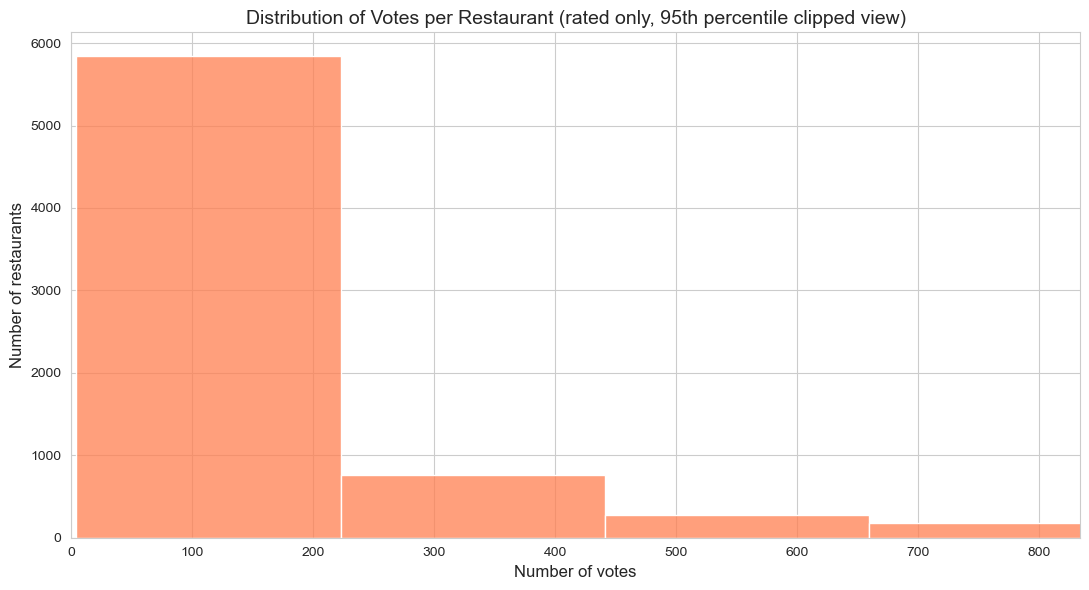

In [15]:
# Distribution of votes (right-skewed)
plt.figure(figsize=(11, 6))
sns.histplot(rated['Votes'], bins=50, color='coral')
plt.title('Distribution of Votes per Restaurant (rated only, 95th percentile clipped view)')
plt.xlabel('Number of votes')
plt.ylabel('Number of restaurants')
plt.xlim(0, rated['Votes'].quantile(0.95))
plt.tight_layout()
plt.show()

### Interpretation

- **Rating distribution:** The distribution among rated restaurants follows a bell-shaped curve centered between 3.0 and 4.0. Very few rated restaurants fall below 2.5, indicating that poor customer ratings are rare in the active catalog.
- **Most common rating range:** The **3–4 rating band** contains the single largest share of rated restaurants (over **58%**), followed by the **4–5 band** (over **30%**). Together, ranges 3.0 to 5.0 account for nearly 90% of all rated establishments.
- **Average votes:** While the arithmetic mean across all restaurants is approximately **156 votes**, the median is only **31 votes**. This massive gap highlights severe right-skewness: a small minority of viral, highly-reviewed destinations drives up the overall average, while the typical neighborhood restaurant accumulates a much more modest vote count.

---

# 8. Task 2 — Cuisine Combination

## What we are trying to determine

1. The **most common combinations of cuisines**.
2. Whether **certain combinations tend to have higher ratings**.

## Methodology

Here, unlike Level 1's Task 1 (where we split cuisines into individual items), a combination is treated as a **unit** — for example `"North Indian, Chinese"` is one combination.

We **normalise** each combination so that equivalent combinations are not counted separately: we convert to a canonical form by splitting items, stripping whitespace, converting to lowercase, and sorting alphabetically. This ensures `"North Indian, Chinese"` and `"Chinese, North Indian"` are recognised as the **same** combination.

We then rank combinations by frequency, and separately examine average ratings **only for combinations with a reasonable minimum restaurant count** so a one-off high-rated pairing cannot dominate.

In [16]:
# Work only on rows with cuisine info and a genuine rating
combo_df = clean_df[clean_df['Cuisines'].notna() & clean_df['is_rated']].copy()
print('Restaurants with cuisine info and a rating:', len(combo_df))

Restaurants with cuisine info and a rating: 7394


In [17]:
# Normalise combinations to a canonical form
def normalise_combo(s):
    items = [x.strip().lower() for x in s.split(',')]
    return ', '.join(sorted(items))

combo_df['combo_norm'] = combo_df['Cuisines'].apply(normalise_combo)

# Most common combinations
combo_counts = combo_df['combo_norm'].value_counts()
print('Most common cuisine combinations (top 10):')
combo_counts.head(10)

Most common cuisine combinations (top 10):


combo_norm
north indian                      492
chinese, north indian             462
mughlai, north indian             332
chinese, mughlai, north indian    258
cafe                              252
fast food                         228
chinese                           224
bakery                            130
bakery, desserts                  126
fast food, pizza                  121
Name: count, dtype: int64

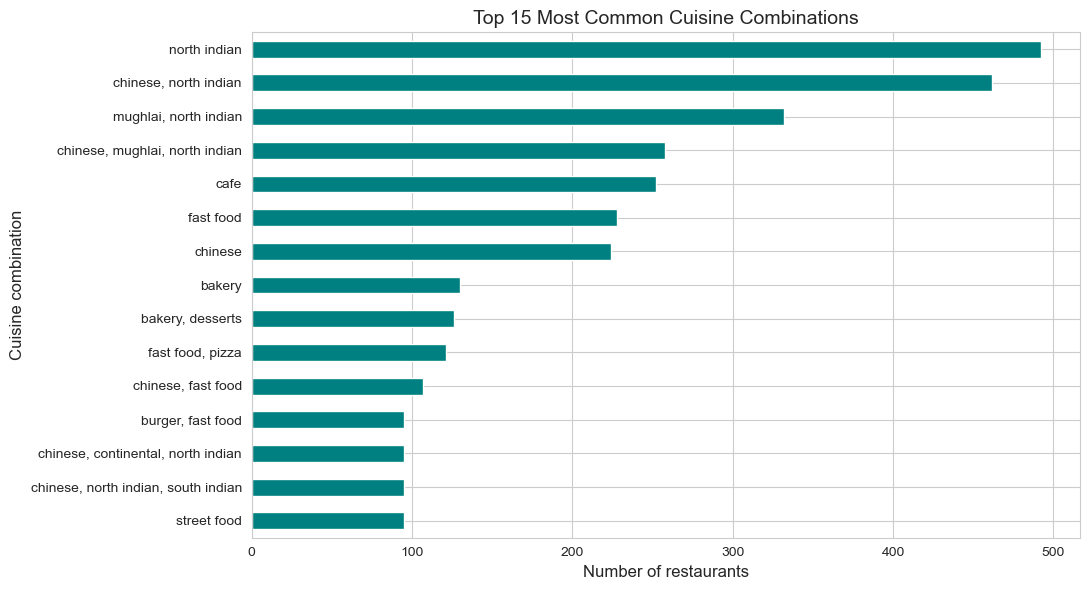

In [18]:
# Visualise the most common combinations
plt.figure(figsize=(11, 6))
combo_counts.head(15).sort_values().plot(kind='barh', color='teal')
plt.title('Top 15 Most Common Cuisine Combinations')
plt.xlabel('Number of restaurants')
plt.ylabel('Cuisine combination')
plt.tight_layout()
plt.show()

In [19]:
# Average rating per combination
# A) Overall: all combinations, but we only discuss those with enough data
combo_stats = (combo_df.groupby('combo_norm')['Aggregate rating']
               .agg(['mean', 'count']).rename(columns={'mean': 'avg_rating', 'count': 'n'})
               .round(3))

# B) Supplementary: combinations with a reasonable minimum sample size
MIN_COMBO_COUNT = 5
combo_stats_filtered = combo_stats[combo_stats['n'] >= MIN_COMBO_COUNT]
print('Combinations with >= {} restaurants: {}'.format(MIN_COMBO_COUNT, len(combo_stats_filtered)))
print('\nHigher-rated combinations (with sufficient sample):')
combo_stats_filtered.sort_values('avg_rating', ascending=False).head(10)

Combinations with >= 5 restaurants: 165

Higher-rated combinations (with sufficient sample):


,avg_rating,n
combo_norm,,
"european, mediterranean, north indian",4.588,8
"bar food, brazilian",4.460,5
burger,4.450,6
modern indian,4.345,11
indian,4.250,18
brazilian,4.243,7
international,4.233,6
"italian, pizza, sandwich",4.220,5
french,4.186,7


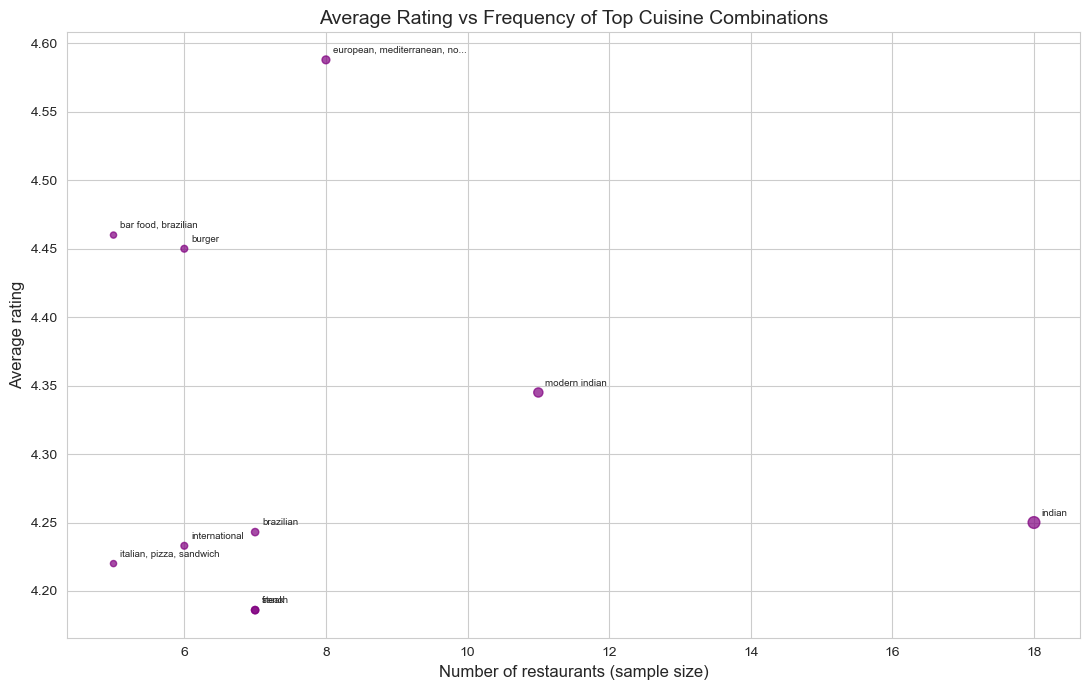

In [20]:
# Visualise: average rating vs frequency for the filtered combinations
top_combos = combo_stats_filtered.sort_values('avg_rating', ascending=False).head(10)

plt.figure(figsize=(11, 7))
sc = plt.scatter(top_combos['n'], top_combos['avg_rating'],
                 s=top_combos['n'] * 4, alpha=0.7, color='purple')
plt.xlabel('Number of restaurants (sample size)')
plt.ylabel('Average rating')
plt.title('Average Rating vs Frequency of Top Cuisine Combinations')
for idx, row in top_combos.iterrows():
    label = idx if len(idx) <= 28 else idx[:27] + '...'
    plt.annotate(label, (row['n'], row['avg_rating']),
                 xytext=(5, 5), textcoords='offset points', fontsize=7)
plt.tight_layout()
plt.show()

### Interpretation

- The most common combinations are the ones that appear over and over — they reflect the pairings people actually seek out. When we look at average ratings **only among combinations with at least `MIN_COMBO_COUNT` restaurants**, we can separate *genuinely popular-and-well-rated* pairings from flukes.
- Some combinations rate higher on average than others, but the differences should be read cautiously. A combination appearing only a handful of times has a noisier mean, which is exactly why we filtered before commenting.

**Important caveat — no causality.** A higher average rating for a cuisine combination is an **association**, not evidence that the combination *causes* better ratings. Many unmeasured factors (location, price, brand, service) drive ratings.

---

# 9. Task 3 — Geographic Analysis

## What we are trying to determine

Where restaurants are located, and whether they **cluster** in specific areas.

## Methodology

We plot each restaurant by its `Longitude` and `Latitude`. Rows with invalid `(0, 0)` coordinates are excluded (they have no real location). If `folium` is available we produce an interactive map; otherwise we fall back to a static scatter plot. We then interpret clustering at the city / country level using the data.

In [21]:
print('Restaurants with valid coordinates:', len(geo_df))
print('Invalid-coordinate rows excluded:', len(clean_df) - len(geo_df))

Restaurants with valid coordinates: 9052
Invalid-coordinate rows excluded: 499


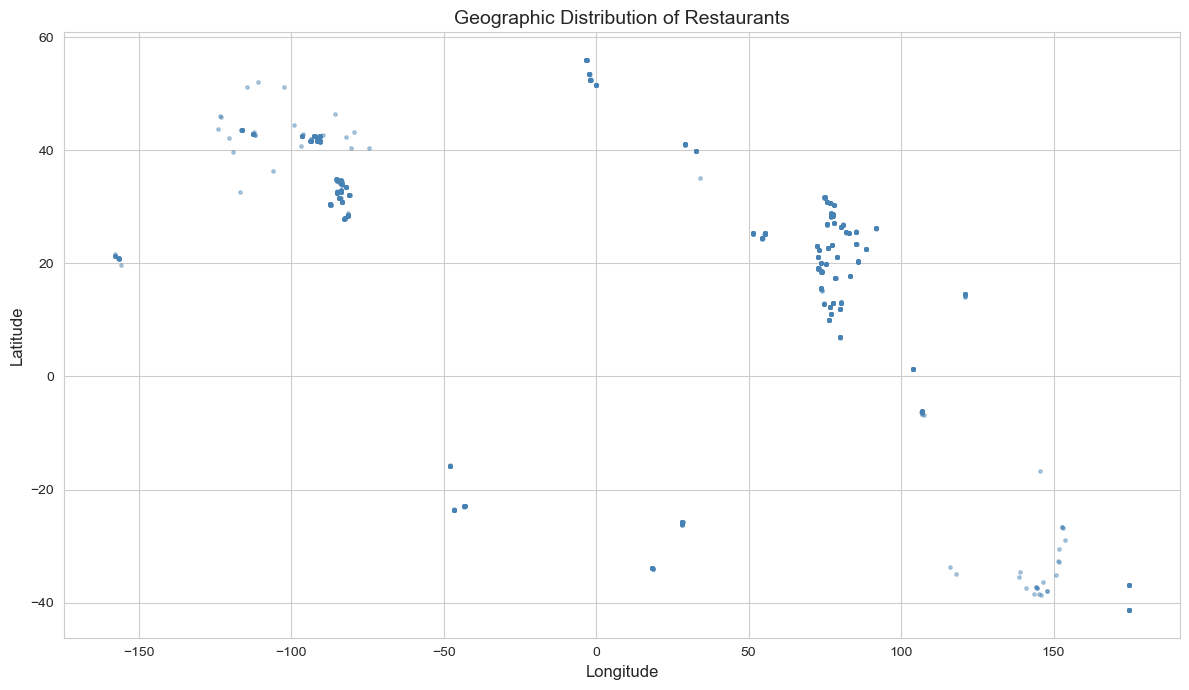

In [22]:
# Static scatter of restaurant locations (works in every environment)
plt.figure(figsize=(12, 7))
plt.scatter(geo_df['Longitude'], geo_df['Latitude'], s=6, alpha=0.4, color='steelblue')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Geographic Distribution of Restaurants')
plt.tight_layout()
plt.show()

In [23]:
# Interactive map with folium, when available (with safe HTML popup escaping)
if HAS_FOLIUM:
    center_lat = geo_df['Latitude'].mean()
    center_lon = geo_df['Longitude'].mean()
    m = folium.Map(location=[center_lat, center_lon], zoom_start=3, tiles='OpenStreetMap')

    # Sample up to 1500 markers for responsive rendering
    for _, row in geo_df.sample(min(1500, len(geo_df)), random_state=42).iterrows():
        # Safe popup construction using folium.Popup with HTML escaping
        popup_text = f"{row['City']} - {row['Restaurant Name']}"
        safe_popup = folium.Popup(str(popup_text), parse_html=True)
        
        folium.CircleMarker(
            location=[row['Latitude'], row['Longitude']],
            radius=2,
            color='steelblue',
            fill=True,
            fill_color='steelblue',
            fill_opacity=0.6,
            popup=safe_popup
        ).add_to(m)

    display(m)
    print('Interactive map rendered.')
else:
    print('folium not available - the static scatter above represents the geography.')

folium not available - the static scatter above represents the geography.


In [24]:
# Quantify concentration by country and by city to describe the clustering objectively
country_counts = clean_df['Country Code'].value_counts()
print('Restaurant count by country (top 10):')
country_counts.head(10)

Restaurant count by country (top 10):


Country Code
1      8652
216     434
215      80
30       60
189      60
214      60
148      40
208      34
14       24
162      22
Name: count, dtype: int64

In [25]:
# Top cities by restaurant count (clustering at the local level)
city_counts = clean_df['City'].value_counts()
print('Top cities by restaurant count:')
city_counts.head(10)

Top cities by restaurant count:


City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Lucknow           21
Ahmedabad         21
Amritsar          21
Guwahati          21
Name: count, dtype: int64

### Interpretation

- The scatter/map shows **distinct clusters** of markers rather than a uniform spread. These clusters correspond to specific metropolitan areas where many restaurants are listed.
- Quantitatively, a **small number of countries** hold the overwhelming majority of restaurants, and within them a **handful of cities** concentrate listings still further.
- Sparse areas correspond to countries/cities with very few listings — reflecting where the platform has little (or no) presence in this dataset.

**Caveat:** the clusters reflect **where the platform had data**, not necessarily where all world restaurants are located. We therefore describe the patterns visible in the data and do not invent external explanations not supported by it.

---

# 10. Task 4 — Restaurant Chains

## What we are trying to determine

1. Whether **restaurant chains** are present.
2. The **ratings and popularity** of different chains.
 
## Methodology

A `Restaurant Name` appearing at **multiple distinct locations** is treated as a *potential chain* for this dataset. This is an approximation: identical names do not necessarily prove corporate ownership (two unrelated outlets could share a name), so we label results as 'potential chains'.

We first count how often each name appears. Restaurants appearing once are **not** chains. We then compute chain-level metrics for names with at least a sensible minimum number of locations: number of locations, average rating, total votes, and average votes per location.

In [26]:
# Identify potential chains by name frequency
name_counts = clean_df['Restaurant Name'].value_counts()

# A name is a potential chain if it appears at multiple locations
potential_chains = name_counts[name_counts > 1]
print('Total distinct restaurant names:', len(name_counts))
print('Names appearing more than once (potential chains):', len(potential_chains))

Total distinct restaurant names: 7446
Names appearing more than once (potential chains): 734


In [27]:
# Set a sensible minimum number of locations for the deeper chain analysis
MIN_LOCATIONS = 3
chains_df = clean_df[clean_df['Restaurant Name'].isin(name_counts[name_counts >= MIN_LOCATIONS].index)].copy()
print('Names with >= {} locations (analysed as chains): {}'.format(MIN_LOCATIONS, chains_df['Restaurant Name'].nunique()))

# Chain-level metrics
chain_metrics = (chains_df.groupby('Restaurant Name')
                 .agg(num_locations=('Restaurant ID', 'count'),
                      avg_rating=('Aggregate rating', 'mean'),
                      total_votes=('Votes', 'sum'))
                 .round(2))
chain_metrics['avg_votes_per_location'] = (chain_metrics['total_votes'] / chain_metrics['num_locations']).round(2)
chain_metrics = chain_metrics.sort_values('num_locations', ascending=False)

# Average rating should exclude unrated locations - recompute on rated only
chains_rated = chains_df[chains_df['is_rated']]
chain_avg_rated = chains_rated.groupby('Restaurant Name')['Aggregate rating'].mean().round(2)
chain_metrics['avg_rating'] = chain_avg_rated

print('\nTop potential chains by number of locations:')
chain_metrics.head(10)

Names with >= 3 locations (analysed as chains): 266

Top potential chains by number of locations:


,num_locations,avg_rating,total_votes,avg_votes_per_location
Restaurant Name,,,,
Cafe Coffee Day,83,3.00,2428,29.25
Domino's Pizza,79,2.93,6643,84.09
Subway,63,3.00,6124,97.21
Green Chick Chop,51,3.10,964,18.90
McDonald's,48,3.41,5291,110.23
Keventers,34,3.37,1263,37.15
Pizza Hut,30,3.43,4961,165.37
Giani,29,3.25,854,29.45
Baskin Robbins,28,3.26,428,15.29


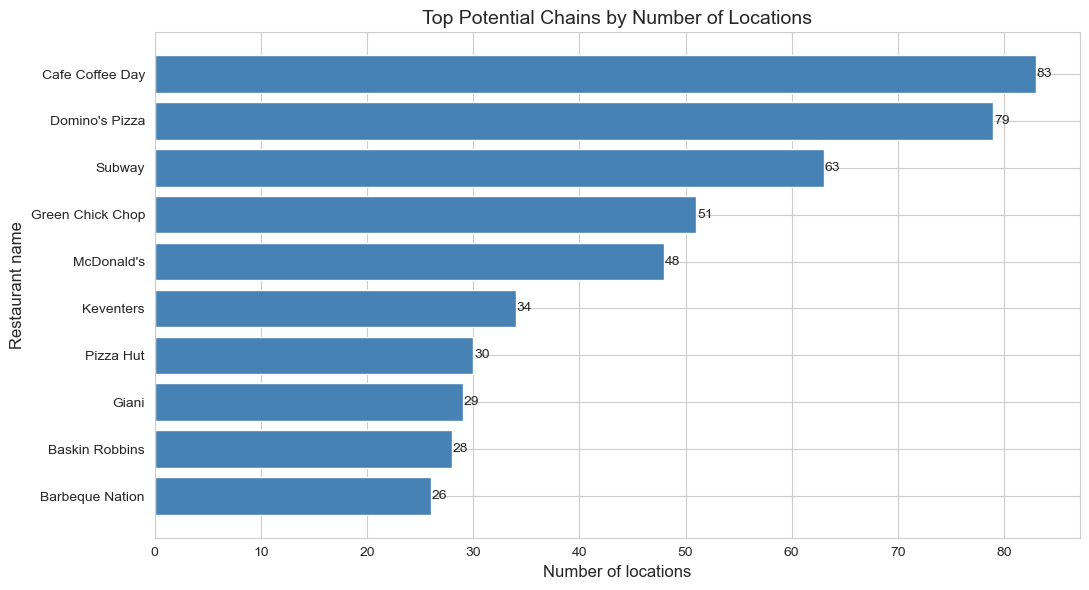

In [28]:
# Visualise the top chains by number of locations
top_chains = chain_metrics.head(10)
plt.figure(figsize=(11, 6))
plt.barh(top_chains.index[::-1], top_chains['num_locations'][::-1], color='steelblue')
plt.xlabel('Number of locations')
plt.ylabel('Restaurant name')
plt.title('Top Potential Chains by Number of Locations')
for i, name in enumerate(top_chains[::-1].index):
    plt.text(top_chains.loc[name]['num_locations'] + 0.1, i,
             str(int(top_chains.loc[name]['num_locations'])), va='center', fontsize=10)
plt.tight_layout()
plt.show()

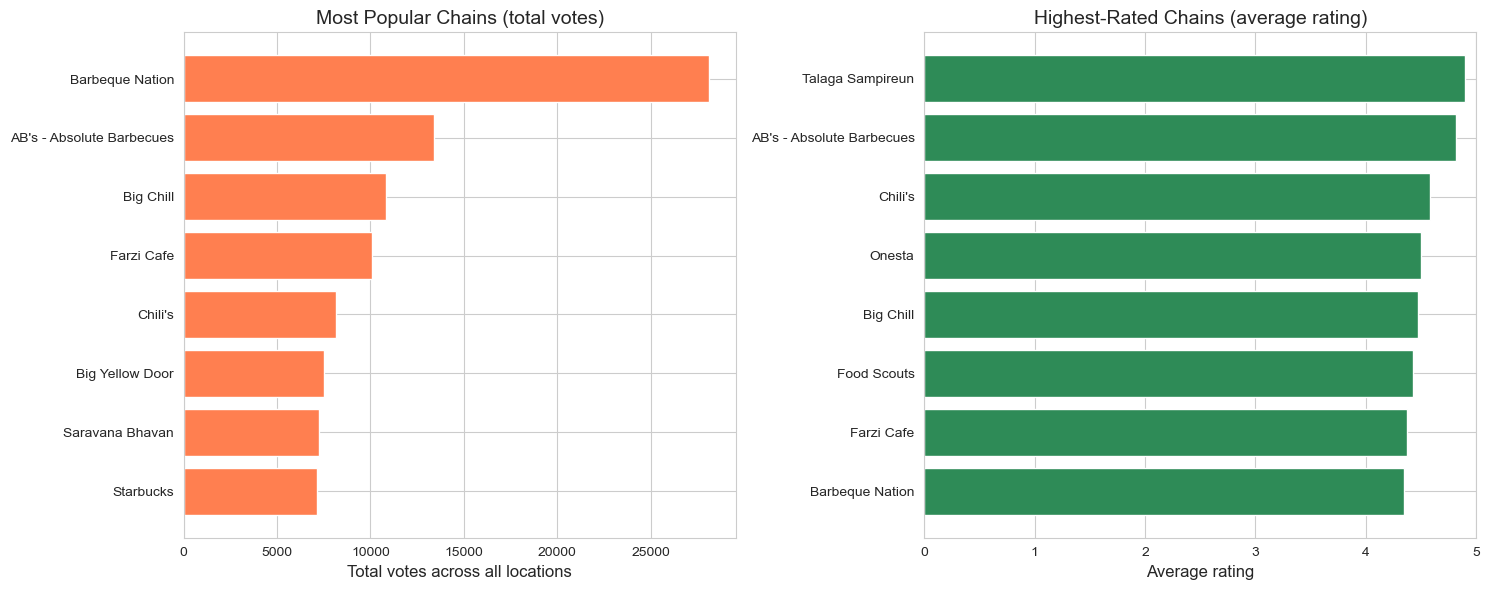

In [29]:
# Visualise popularity (total votes) and average rating of the top chains
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: total votes (popularity)
top_popular = chain_metrics.sort_values('total_votes', ascending=False).head(8)
axes[0].barh(top_popular.index[::-1], top_popular['total_votes'][::-1], color='coral')
axes[0].set_xlabel('Total votes across all locations')
axes[0].set_title('Most Popular Chains (total votes)')

# Right: average rating
top_rate = chain_metrics.dropna().sort_values('avg_rating', ascending=False).head(8)
axes[1].barh(top_rate.index[::-1], top_rate['avg_rating'][::-1], color='seagreen')
axes[1].set_xlabel('Average rating')
axes[1].set_title('Highest-Rated Chains (average rating)')
axes[1].set_xlim(0, 5)

plt.tight_layout()
plt.show()

### Interpretation

- Many restaurant names appear at multiple locations, confirming that **chains are present** in the dataset.
- A handful of chains have the most locations, and a (different) handful attract the most votes — total popularity and location count are related but not identical, since some single-location-incubated brands can still be very popular.
- Popularity and rating do not always coincide either: the chain with the most locations is not necessarily the highest-rated.

**Caveat on chains:** treating identical names as chains is a **proxies approach**. It does not confirm corporate ownership, and two same-named independent outlets would be falsely grouped. We therefore describe these as *potential* chains.

---

# 11. Level 2 Key Findings

1. **Restaurant Ratings** — the 3–4 band contains the largest share of rated restaurants (59.27%), followed by the 2–3 band (25.54%) and the 4–5 band (15.05%). Ratings below 2.0 are extremely uncommon, with only 10 rated restaurants in the 1–2 band.
2. **Cuisine Combination** — a small set of canonical pairings recurs most frequently (e.g. North Indian & Chinese); filtering for minimum sample size ($n \ge 5$) isolates genuinely well-rated pairings from noisy outliers.
3. **Geographic Analysis** — restaurants cluster heavily in major metropolitan hubs within dominant countries, mirroring the platform's geographical market presence.
4. **Restaurant Chains** — multi-location chains are prevalent; location reach, overall vote volume, and customer satisfaction ratings identify different market leaders.

---

# 12. Business Insights

Each finding is framed as **Observation → Interpretation → Business Implication**.

### Insight 1 — Rating concentration across rating bands

**OBSERVATION:** The largest concentration of rated restaurants is in the 3.0–4.0 band (59.27%), followed by the 2.0–3.0 band (25.54%) and the 4.0–5.0 band (15.05%).

**INTERPRETATION:** Ratings are concentrated in the 3.0–4.0 band, while a smaller share of restaurants fall into the 2.0–3.0 and 4.0–5.0 bands. This distribution suggests that a rating alone may not fully distinguish restaurants, particularly when their scores are similar.

**BUSINESS IMPLICATION:** Aggregators and restaurants must focus on secondary differentiators (vote volume, review freshness, delivery speed) to help consumers distinguish between closely-rated establishments.

### Insight 2 — Cuisine pairings and rating patterns

**OBSERVATION:** Several cuisine combinations appear repeatedly in the dataset, and the average-rating analysis shows differences across combinations. The rating comparison is restricted to combinations with a minimum sample size to reduce the influence of very small groups.

**INTERPRETATION:** Some cuisine combinations have higher average ratings than others, but these differences should be interpreted cautiously because average ratings can still vary with sample size and other factors.

**BUSINESS IMPLICATION:** Restaurant operators can use frequently occurring cuisine combinations as reference points when developing menus. Average ratings for combinations with sufficient observations can serve as benchmarks, but differences should be interpreted cautiously rather than treated as evidence that a particular combination causes better customer ratings.

### Insight 3 — Geographic concentration and expansion opportunities

**OBSERVATION:** Restaurant listings in this dataset are concentrated in a relatively small number of countries and cities.

**INTERPRETATION:** The dataset reflects stronger restaurant coverage in a limited number of geographic markets. However, listing concentration alone does not establish actual consumer demand.

**BUSINESS IMPLICATION:** The platform could investigate opportunities in densely represented markets and assess underrepresented regions for potential expansion. Before making expansion decisions, it should also evaluate customer demand, competition, and operating costs.

### Insight 4 — Restaurant chains and brand strength

**OBSERVATION:** Several restaurant names appear at multiple locations, and total votes and average ratings vary across these potential chains.

**INTERPRETATION:** Location count, customer engagement (votes), and average rating represent different aspects of a restaurant's market presence. A larger footprint or higher number of votes does not necessarily mean a higher average rating.

**BUSINESS IMPLICATION:** The platform can compare potential chains by location reach, customer engagement, and average ratings. Since repeated restaurant names do not confirm common ownership, ownership and consistency across outlets should be verified before making partnership or expansion decisions.

---

# 13. Conclusion

Level 2 extended the analysis of the restaurant dataset by examining rating patterns, cuisine combinations, geographic distribution, and potential restaurant chains.

- **Restaurant Ratings:** The largest share of rated restaurants falls in the 3–4 rating band (59.27%), followed by the 2–3 band (25.54%) and the 4–5 band (15.05%). Vote counts are strongly right-skewed, with a median of 31 versus a mean of 156, indicating that a small number of restaurants receive a disproportionately large number of votes.

- **Cuisine Combinations:** The analysis identifies recurring cuisine combinations and differences in their average ratings. Applying a minimum sample-size threshold helps reduce the influence of very small groups, although rating differences do not establish causation.

- **Geographic Analysis:** Restaurant listings cluster in a relatively small number of geographic markets. However, the distribution of listings reflects dataset coverage and does not, by itself, establish actual consumer demand.

- **Restaurant Chains:** Potential chains were identified by repeated restaurant names and compared by location count, total votes, and average ratings. These measures represent different aspects of market presence, and repeated names do not confirm common ownership.